# Compétition 1 : Prédiction de la Qualité de la Bière 🍺

Ce notebook fournit du code de démarrage pour la compétition de prédiction de la qualité de la bière. Pour les instructions complètes, l'énoncé du problème et les critères de notation, veuillez vous référer au fichier **README.md**.

**Résumé rapide** : Vous allez construire un modèle de classification pour prédire la qualité de la bière (scores 1-10) basé sur des propriétés chimiques. Soumettez vos prédictions sur [Kaggle](https://www.kaggle.com/competitions/ift-6390-ift-3395-beer-quality-prediction/).

## Importer les Dépendances

In [175]:
# Importer les bibliothèques requises
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

## Charger et Explorer les Données

In [176]:
# Charger les données d'entraînement
train_df = pd.read_csv('data/train.csv', delimiter=';')

print(f"Forme des données d'entraînement : {train_df.shape}")
print(f"Nombre d'échantillons (n) : {train_df.shape[0]}")
print(f"Nombre de caractéristiques (d) : {train_df.shape[1] - 1}")  # Soustraire 1 pour la colonne cible
print(f"Colonnes : {list(train_df.columns)}")
print("\nPremières lignes :")
print(train_df.head())

# Vérifier les types de données et informations de base
print("\nTypes de données et informations :")
print(train_df.info())

####################################################################
###############   À compléter   ####################################
####################################################################

Forme des données d'entraînement : (4469, 15)
Nombre d'échantillons (n) : 4469
Nombre de caractéristiques (d) : 14
Colonnes : ['id', 'beer_style', 'bitterness_IBU', 'diacetyl_concentration', 'lactic_acid', 'final_gravity', 'sodium', 'free_CO2', 'dissolved_oxygen', 'original_gravity', 'pH', 'gypsum_level', 'alcohol_ABV', 'fermentation_strength', 'quality']

Premières lignes :
   id beer_style  bitterness_IBU  diacetyl_concentration  lactic_acid  \
0   0       Pale           7.997                   0.446        0.280   
1   1       Pale           6.906                   0.222        0.303   
2   2      Brown           7.183                   0.636        0.071   
3   3       Pale           6.403                   0.242        0.260   
4   4      Brown           7.917                   0.182        0.347   

   final_gravity  sodium  free_CO2  dissolved_oxygen  original_gravity     pH  \
0         10.803   0.052    24.999           157.026             0.995  3.057   
1          6.305   0.

## Prétraitement des Données

Implémentez votre pipeline de prétraitement (voir README.md pour des suggestions).

In [ ]:
####################################################################
###############   À compléter   ####################################
####################################################################

# Encodage de la variable catégorielle 'beer_style'
le = LabelEncoder()
train_df['beer_style'] = le.fit_transform(train_df['beer_style'])

# La classification officiel est entre 4 et 8, on se concentre donc sur cette plage compte tenu que les classes
# en dehors sont très peu représentées ou possiblement du bruit
rl_df = train_df[train_df['quality'].between(4,8)]
'bitterness_IBU', 'diacetyl_concentration', 'lactic_acid', 'sodium',
       'free_CO2', 'original_gravity', 'gypsum_level', 'alcohol_ABV',
       'gas_balance', 'mineral_strength', 'fermentation_ratio', 'acid_x_gas',
       'log_gravity_drop'
# ========================================= Nouvelles features =========================================
rl_df['gas_balance'] = rl_df['free_CO2'] / (rl_df['dissolved_oxygen'] + 1e-5)
rl_df['mineral_strength'] = rl_df['gypsum_level'] * rl_df['sodium']
rl_df['fermentation_ratio'] = rl_df['fermentation_strength'] / (rl_df['alcohol_ABV'] + 1e-5)
rl_df['acid_balance'] = rl_df['lactic_acid'] / (rl_df['pH'] + 1e-5) # out 
rl_df['acid_x_gas'] = rl_df['acid_balance'] * rl_df['gas_balance']
rl_df['gravity_drop'] = rl_df['original_gravity'] - rl_df['final_gravity'] # out 
rl_df['log_gravity_drop'] = np.log1p(rl_df['gravity_drop'].clip(lower=0))
rl_df = rl_df.drop(columns=['bitterness_IBU','diacetyl_concentration'], errors='ignore')

#========================================= Legacy features =========================================
# rl_df['log_final_gravity'] = np.log1p(rl_df['final_gravity']) # out
#rl_df['acid_balance'] = rl_df['lactic_acid'] / (rl_df['pH'] + 1e-5) # out 
# rl_df['alcohol_efficiency'] = rl_df['alcohol_ABV'] / (rl_df['gravity_drop'] + 1e-5) # out 
# rl_df['residual_sugar_index'] = rl_df['final_gravity'] / (rl_df['original_gravity'] + 1e-5) # out 
# rl_df['lactic_intensity'] = rl_df['lactic_acid'] * rl_df['fermentation_strength'] # out 
# rl_df['acid_x_gravity'] = rl_df['acid_balance'] * rl_df['gravity_drop'] # out
# rl_df['sqrt_alcohol_eff'] = np.sqrt(rl_df['alcohol_efficiency'].clip(lower=0)) # out 


## Visualisations
## Decommenter pour voir les corrélations entre les features et la qualité
"""
corr = train_df.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', center=0)
sns.pairplot(rl_df[['lactic_acid','pH','alcohol_ABV','final_gravity','quality']], hue='quality')
plt.figure(figsize=(10,6))
sns.heatmap(rl_df[['gravity_drop','acid_balance','gas_balance','quality']].corr(),
            annot=True, cmap='coolwarm', center=0)
plt.title("Corrélations des nouvelles features avec la qualité")
plt.show()

corr2 = rl_df[['acid_x_gas','log_gravity_drop','quality']].corr()
sns.heatmap(corr2, annot=True, cmap='coolwarm', center=0)
plt.title("Corrélations des features non linéaires avec la qualité")
plt.show()
"""

# Suppression des features à faible corrélation avec la cible et des features redondantes
# Suppression des features à faible corrélation avec la cible
corr_target = rl_df.corr(numeric_only=True)['quality'].abs().sort_values(ascending=False)
low_corr_features = corr_target[corr_target < 0.05].index
rl_df = rl_df.drop(columns=low_corr_features, errors='ignore')

# Suppression des features redondantes (corrélation > 0.9)
corr_matrix = rl_df.corr(numeric_only=True).abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_features = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]

features_to_drop = list(set(list(low_corr_features) + list(high_corr_features)))
rl_df = rl_df.drop(columns=high_corr_features, errors='ignore')
print("Features supprimées :", features_to_drop)

# Gestion des valeurs manquantes et infinies
rl_df = rl_df.replace([np.inf, -np.inf], np.nan)
rl_df = rl_df.dropna(subset=['quality'])
rl_df = rl_df.fillna(rl_df.mean())

# Préparation des données pour le modèle
if 'id' in rl_df.columns:
    rl_df =rl_df.drop(columns=['id'])

X = rl_df.drop(columns=['quality'])
y = rl_df['quality']

# Normalisation des features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


print(X.shape, y.shape)
print(f"shape finale de X : {X.shape}")
print('Distribution des classes de qualité :')
print(y.value_counts())


Features supprimées : ['gravity_drop', 'fermentation_strength', 'pH', 'id', 'final_gravity', 'beer_style', 'acid_balance', 'dissolved_oxygen']
(4445, 13) (4445,)
shape finale de X : (4445, 13)
Distribution des classes de qualité :
quality
6    1985
5    1496
7     755
4     116
8      93
Name: count, dtype: int64


/var/folders/y5/5rmdtyp17yz4dz_hjr0z9d600000gn/T/ipykernel_58184/3149733455.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rl_df['gas_balance'] = rl_df['free_CO2'] / (rl_df['dissolved_oxygen'] + 1e-5)
/var/folders/y5/5rmdtyp17yz4dz_hjr0z9d600000gn/T/ipykernel_58184/3149733455.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rl_df['mineral_strength'] = rl_df['gypsum_level'] * rl_df['sodium']
/var/folders/y5/5rmdtyp17yz4dz_hjr0z9d600000gn/T/ipykernel_58184/3149733455.py:16: SettingWithCopyWarning: 


## Préparer les Données d'Entraînement et de Validation

Divisez vos données en ensembles d'entraînement et de validation.

In [178]:
####################################################################
###############   À compléter   ####################################
####################################################################
print(y.value_counts())
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size = 0.2, stratify=y,random_state=42)



quality
6    1985
5    1496
7     755
4     116
8      93
Name: count, dtype: int64


## Entraîner les Modèles

Entraînez et comparez plusieurs modèles d'apprentissage automatique.

In [179]:
"""
def knnModel():
    for k in range(1, 100):
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        print(f"k={k}, accuracy={accuracy_score(y_val, y_pred):.4f}")

    knn = KNeighborsClassifier(
        n_neighbors=27,
        weights='distance',
        metric='euclidean'
    )

    knn.fit(X_train, y_train)
"""

'\ndef knnModel():\n    for k in range(1, 100):\n        model = KNeighborsClassifier(n_neighbors=k)\n        model.fit(X_train, y_train)\n        y_pred = model.predict(X_val)\n        print(f"k={k}, accuracy={accuracy_score(y_val, y_pred):.4f}")\n\n    knn = KNeighborsClassifier(\n        n_neighbors=27,\n        weights=\'distance\',\n        metric=\'euclidean\'\n    )\n\n    knn.fit(X_train, y_train)\n'

In [180]:

rf = RandomForestClassifier(
    n_estimators=4000, 
    max_depth=None, 
    class_weight='balanced_subsample', 
    random_state=42)
rf.fit(X_train, y_train)



,n_estimators,4000
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [181]:
svm = SVC(C=10.0, 
          kernel='rbf', 
          gamma='scale',
          class_weight='balanced', 
          probability=True)
svm.fit(X_train, y_train)

,C,10.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [182]:
####################################################################
###############   À compléter   ####################################
####################################################################

# Logistic Regression Model
log_reg = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    C=1.5,
    class_weight='balanced',
    max_iter=3000
)

log_reg.fit(X_train, y_train)




/Users/yamira.poldosilva/Documents/UDEM/A25/IFT3395/kaggle_beer_comp/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.5
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,3000
,multi_class,'multinomial'


## Évaluer les Modèles

Analysez la performance de votre meilleur modèle (voir README.md pour les directives d'évaluation).

Exactitude: 0.36332958380202474
              precision    recall  f1-score   support

           4       0.08      0.57      0.15        23
           5       0.56      0.51      0.54       299
           6       0.64      0.22      0.33       397
           7       0.34      0.41      0.37       151
           8       0.05      0.37      0.09        19

    accuracy                           0.36       889
   macro avg       0.34      0.42      0.29       889
weighted avg       0.54      0.36      0.40       889



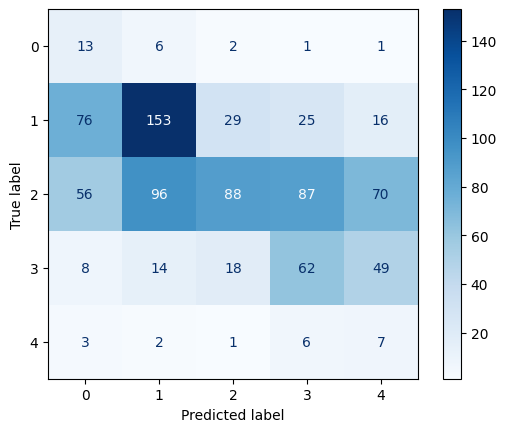

In [183]:
####################################################################
###############   À compléter   ####################################
####################################################################
from sklearn.metrics import ConfusionMatrixDisplay
y_pred = log_reg.predict(X_val)
print("Exactitude:", accuracy_score(y_val,y_pred))
print(classification_report(y_val, y_pred))

cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.show()

## Générer les Prédictions pour la Soumission Kaggle

Créez un fichier CSV avec les colonnes : `id` et `quality` (voir README.md pour les détails du format).

In [184]:

####################################################################
###############   À compléter   ####################################
####################################################################

# Charger les données de test
test_df = pd.read_csv("data/test.csv", sep=";")

# Encodage du style avec le même LabelEncoder
test_df['beer_style'] = le.transform(test_df['beer_style'])

# Créer les mêmes features dérivées
test_df['gravity_drop'] = test_df['original_gravity'] - test_df['final_gravity']
test_df['log_final_gravity'] = np.log1p(test_df['final_gravity'])
test_df['acid_balance'] = test_df['lactic_acid'] / (test_df['pH'] + 1e-5)
test_df['gas_balance'] = test_df['free_CO2'] / (test_df['dissolved_oxygen'] + 1e-5)
test_df['mineral_strength'] = test_df['gypsum_level'] * test_df['sodium']
test_df['alcohol_efficiency'] = test_df['alcohol_ABV'] / (test_df['gravity_drop'] + 1e-5)
test_df['residual_sugar_index'] = test_df['final_gravity'] / (test_df['original_gravity'] + 1e-5)
test_df['fermentation_ratio'] = test_df['fermentation_strength'] / (test_df['alcohol_ABV'] + 1e-5)
test_df['lactic_intensity'] = test_df['lactic_acid'] * test_df['fermentation_strength']
test_df['acid_x_gas'] = test_df['acid_balance'] * test_df['gas_balance']
test_df['acid_x_gravity'] = test_df['acid_balance'] * test_df['gravity_drop']
test_df['log_gravity_drop'] = np.log1p(test_df['gravity_drop'].clip(lower=0))
test_df['sqrt_alcohol_eff'] = np.sqrt(test_df['alcohol_efficiency'].clip(lower=0))



test_df = test_df.replace([np.inf, -np.inf], np.nan)
test_df = test_df.fillna(test_df.mean())

# Sauvegarde de l'id pour la soumission
ids = test_df['id']
X_test = test_df.drop(columns=['id'])

# Assurer que les colonnes du test correspondent à celles du train
for col in X.columns:
    if col not in X_test.columns:
        test_df[col] = 0
X_test = test_df[X.columns]
print('les colonnes:', X_test.columns)
X_test_scaled = scaler.transform(X_test)


# Prédiction sur le test set
y_pred = log_reg.predict(X_test_scaled)

print("Test shape:", X_test_scaled.shape)

submission = pd.DataFrame({
    'id': ids,
    'quality': y_pred.astype(int)
})

# Sauvegarde
submission.to_csv("ift3395_YamirPoldoSilvaV5.csv", index=False)

print(submission.head())

df1 = pd.read_csv("ift3395_YamirPoldoSilvaV2.csv")
df2 = pd.read_csv("ift3395_YamirPoldoSilvaV4.csv")

comparison = df1.compare(df2)
print(comparison)


les colonnes: Index(['bitterness_IBU', 'diacetyl_concentration', 'lactic_acid', 'sodium',
       'free_CO2', 'original_gravity', 'gypsum_level', 'alcohol_ABV',
       'gas_balance', 'mineral_strength', 'fermentation_ratio', 'acid_x_gas',
       'log_gravity_drop'],
      dtype='object')
Test shape: (511, 13)
   id  quality
0   0        5
1   1        5
2   2        7
3   3        7
4   4        8
    quality      
       self other
0       6.0   5.0
5       5.0   4.0
8       7.0   4.0
14      6.0   7.0
17      4.0   8.0
..      ...   ...
475     8.0   7.0
482     8.0   7.0
483     4.0   5.0
489     7.0   8.0
501     8.0   4.0

[109 rows x 2 columns]


---
Bonne chance pour la compétition ! 🍺
